# Traffic Sign Classification

Real GTSRB (German Traffic Sign Recognition Benchmark, 43 classes). `torchvision.datasets.GTSRB` has been flaky for me, so I read the parquet copy at `tanganke/gtsrb` on Hugging Face, which keeps the official train (26,640) and test (12,630) splits and adds readable class names.

To stay CPU-friendly I take up to two 100-image row groups per class from train (8,340 images) and a random 4,000 images from the official test split, all resized to 48x48. Using the official test split matters here: GTSRB train images come in tracks of ~30 near-identical frames of the same physical sign, so a random train/test split would leak. A small CNN, since signs are mostly about shape + color, trained for 4 epochs.

In [1]:
import io
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem
from PIL import Image
from sklearn.metrics import classification_report, accuracy_score, f1_score

torch.set_num_threads(2)
np.random.seed(13); torch.manual_seed(13)

In [2]:
SIZE = 48
fs = HfFileSystem()
def pf_for(split):
    return pq.ParquetFile(fs.open(f"datasets/tanganke/gtsrb/data/{split}-00000-of-00001.parquet"))

meta = pf_for("train").schema_arrow.metadata[b"huggingface"]
import json
SIGN_CLASSES = json.loads(meta)["info"]["features"]["label"]["names"]

def decode(rows):
    X = np.stack([np.asarray(Image.open(io.BytesIO(r["image"]["bytes"])).convert("RGB").resize((SIZE, SIZE)),
                             dtype=np.float32) / 255.0 for r in rows])
    return X, np.array([r["label"] for r in rows], dtype=np.int64)

# train: the file is sorted by class, so pick up to 2 row groups per class
pf = pf_for("train")
first_label = [pf.read_row_group(g, columns=["label"]).column("label")[0].as_py() for g in range(pf.metadata.num_row_groups)]
groups = []
for c in range(len(SIGN_CLASSES)):
    gs = [g for g, l in enumerate(first_label) if l == c]
    groups += [gs[i] for i in sorted(set(np.linspace(0, len(gs) - 1, 2).astype(int)))]
X_train, y_train = decode([r for g in groups for r in pf.read_row_group(g).to_pylist()])

# test: random 4,000 from the official test split
pft = pf_for("test")
test_rows = pft.read().to_pylist()
pick = np.random.default_rng(13).choice(len(test_rows), 4000, replace=False)
X_test, y_test = decode([test_rows[i] for i in pick])
del test_rows
print('train:', X_train.shape, '| test:', X_test.shape, '| classes:', len(SIGN_CLASSES))

train: (8340, 48, 48, 3) | test: (4000, 48, 48, 3) | classes: 43


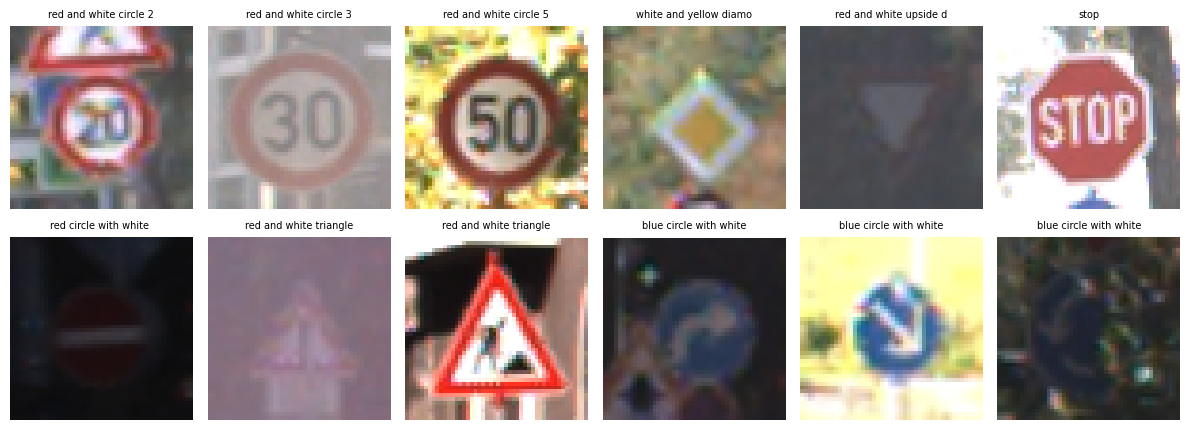

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, c in zip(axes.flat, [0, 1, 2, 12, 13, 14, 17, 18, 25, 33, 38, 40]):
    ax.imshow(X_train[np.where(y_train == c)[0][0]])
    ax.set_title(SIGN_CLASSES[c][:22], fontsize=7); ax.axis('off')
plt.tight_layout(); plt.show()

In [4]:
Xtr = torch.tensor(X_train).permute(0, 3, 1, 2); ytr = torch.tensor(y_train)
Xte = torch.tensor(X_test).permute(0, 3, 1, 2); yte = torch.tensor(y_test)

class SignCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.c1 = nn.Conv2d(3, 16, 3, padding=1)
        self.c2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(32 * 12 * 12, 64)
        self.fc2 = nn.Linear(64, n_classes)
        self.drop = nn.Dropout(0.3)

    def forward(self, x):
        x = self.pool(F.relu(self.c1(x)))
        x = self.pool(F.relu(self.c2(x)))
        x = x.flatten(1)
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)

model = SignCNN(len(SIGN_CLASSES))
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

batch = 32
for ep in range(4):
    model.train(); perm = torch.randperm(len(Xtr)); losses = []
    for i in range(0, len(perm), batch):
        idx = perm[i:i + batch]
        opt.zero_grad()
        out = model(Xtr[idx])
        loss = F.cross_entropy(out, ytr[idx])
        loss.backward(); opt.step()
        losses.append(loss.item())
    print(f'epoch {ep}  mean_loss={np.mean(losses):.4f}')

epoch 0  mean_loss=3.0235


epoch 1  mean_loss=1.4287


epoch 2  mean_loss=0.8077


epoch 3  mean_loss=0.5715


In [5]:
model.eval()
with torch.no_grad():
    preds = torch.cat([model(Xte[i:i + 256]).argmax(1) for i in range(0, len(Xte), 256)]).numpy()
print(f"test accuracy: {accuracy_score(yte.numpy(), preds):.3f}   macro-F1: {f1_score(yte.numpy(), preds, average='macro'):.3f}")
per_class = pd.Series(f1_score(yte.numpy(), preds, average=None, labels=range(len(SIGN_CLASSES))),
                      index=SIGN_CLASSES)
print("\nfive weakest classes by F1:")
print(per_class.sort_values().head(5).round(3))

test accuracy: 0.578   macro-F1: 0.577

five weakest classes by F1:
red and white triangle with person walking warning            0.125
red and white triangle with snowflake / ice warning           0.140
red and white circle 80 kph speed limit                       0.161
red and white circle 30 kph speed limit                       0.181
red and white triangle with merging / narrow lanes warning    0.278
dtype: float64


## Takeaways

On 4,000 images from the official GTSRB test split, the small CNN gets 57.8% accuracy and 0.577 macro-F1 after 4 epochs. Training loss fell to 0.57, so there's a big gap between what it fits and what it generalizes to. My guess is that the cause is the sampling: two row groups per class means the model only sees a handful of physical signs per class (each GTSRB track is ~30 frames of one sign), so it learns those specific signs and their backgrounds rather than the class.

The weakest classes back up the color-and-shape story. They are the ones that share both with other classes and differ only in a small pictogram or digit: "pedestrian" and "snow / ice" warnings (same red-and-white triangle as a dozen others) and the 30 and 80 km/h limits (same red circle as the other speed limits). At 48x48 those inner details are a few pixels wide.

To do better I'd: (1) train on all 26,640 training images instead of a slice, so every class has many tracks, (2) add color jitter and small rotations (real signs are photographed at angles), (3) use class-balanced sampling, since GTSRB is heavily imbalanced, and (4) a few more epochs. Published small CNNs on full GTSRB reach well above 95%.